In [1]:
import sys
sys.path.append("../src")
from utils import *

In [2]:
adata = sc.read(os.path.join(datadir, "anca_samples_processed.h5ad"))

In [3]:
res = 2
sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", random_state=seed)

In [4]:
sc.set_figure_params(dpi=100)
plt.rcParams["font.family"] = ["Arial"]

In [5]:
from matplotlib import font_manager
av_fonts = [fontpath.split("/")[-1] for fontpath in font_manager.findSystemFonts(fontpaths=None, fontext='ttf')]

In [6]:
font_dirs = "/usr/share/fonts/truetype/msttcorefonts/"
font_files = font_manager.findSystemFonts(fontpaths=font_dirs)

In [7]:
# custom_font_manager = matplotlib.font_manager.FontManager()
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

In [8]:
import matplotlib

In [9]:
matplotlib.pyplot.rcParams['font.family'] = "arial"
# matplotlib.pyplot.rcParams['font.weight'] = "regular"

matplotlib.pyplot.rcParams['figure.dpi'] = 100
matplotlib.pyplot.rcParams['figure.figsize'] = [5,5]

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


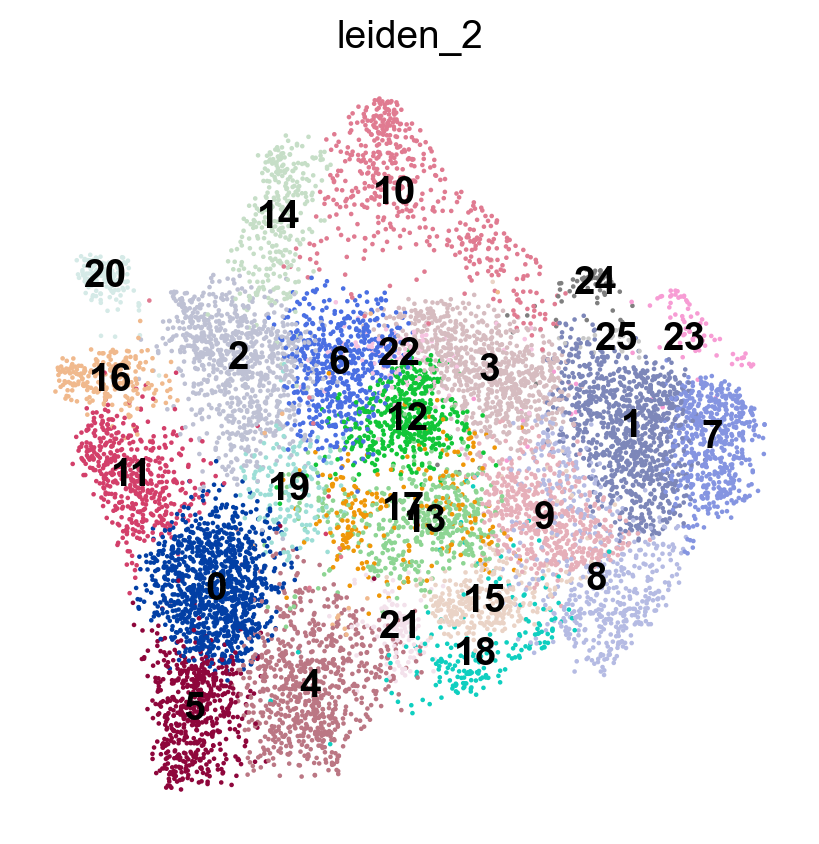

In [10]:
sc.pl.umap(adata, color=f"leiden_{res}", legend_loc="on data", show=False, frameon=False)
color = f"leiden_{res}"
#plt.savefig(os.path.join(figdir, f"UMAP_anca_samples_coloredBy{color}_on_top.pdf"), bbox_inches="tight")

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


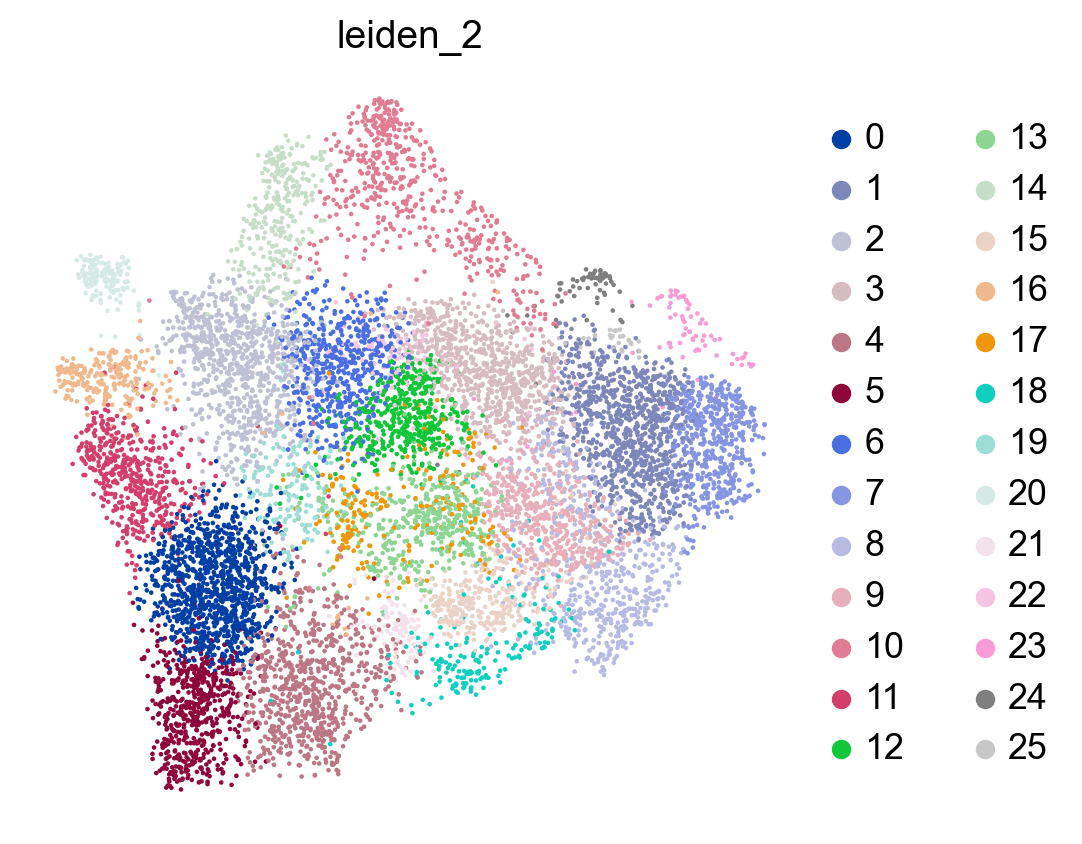

In [11]:
# sc.set_figure_params(dpi=100)
sc.pl.umap(adata, color=color, show=False, frameon=False)
plt.savefig(os.path.join(figdir, f"UMAP_anca_samples_coloredBy{color}_on_side.pdf"), bbox_inches="tight")

In [12]:
# show embeddings of each cluster separately

In [13]:
tmp = adata.copy()
sc.pp.scale(tmp, max_value=10)

In [14]:
tmp_dict = {"PT": ["LRP2", "CUBN", "SLC13A1"],
               "Thin limb": ["CRYAB", "TACSTD2", "SLC44A5", "KLRG2", "COL26A1", "BOC"],
               "TAL": ["CASR", "SLC12A1", "UMOD"],
               "DCT": ["SLC12A3", "CNNM2", "FGF13", "KLHL3", "LHX1", "TRPM6"],
               "CNT": ["SLC8A1", "SCN2A", "HSD11B2", "CALB1"],
               "PC": ["GATA3", "AQP2", "AQP3"],
               "IC": ["ATP6V0D2", "ATP6V1C2", "TMEM213", "CLNK"],
               "Endo": ["CD34", "PECAM1", "PTPRB", "MEIS2", "FLT1", "EMCN"],
               "vSMC/Pericyte": ["NOTCH3", "PDGFRB", "ITGA8"],
               "Fibroblast": ["COL1A1", "COL1A2", "C7", "NEGR1", "FBLN5", "DCN", "CDH11"],
               "Immune": ["PTPRC", "CD3D", "CD14", "CD19"],
               "Schwann": ["CDH19", "NRXN1", "GINS3"],
               "Podocyte": ["PTPRQ", "WT1", "NTNG1", "NPHS1", "NPHS2", "CLIC5", "PODXL"]
                             }

markers_dict = {}
for key in tmp_dict:
    genes = []
    for gene in tmp_dict[key]:
        if gene in adata.var_names:
            genes.append(gene)
    markers_dict[key] = genes

categories: 0, 1, 2, etc.
var_group_labels: PT, Thin limb, TAL, etc.


/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:105: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(adata.obs[group]):

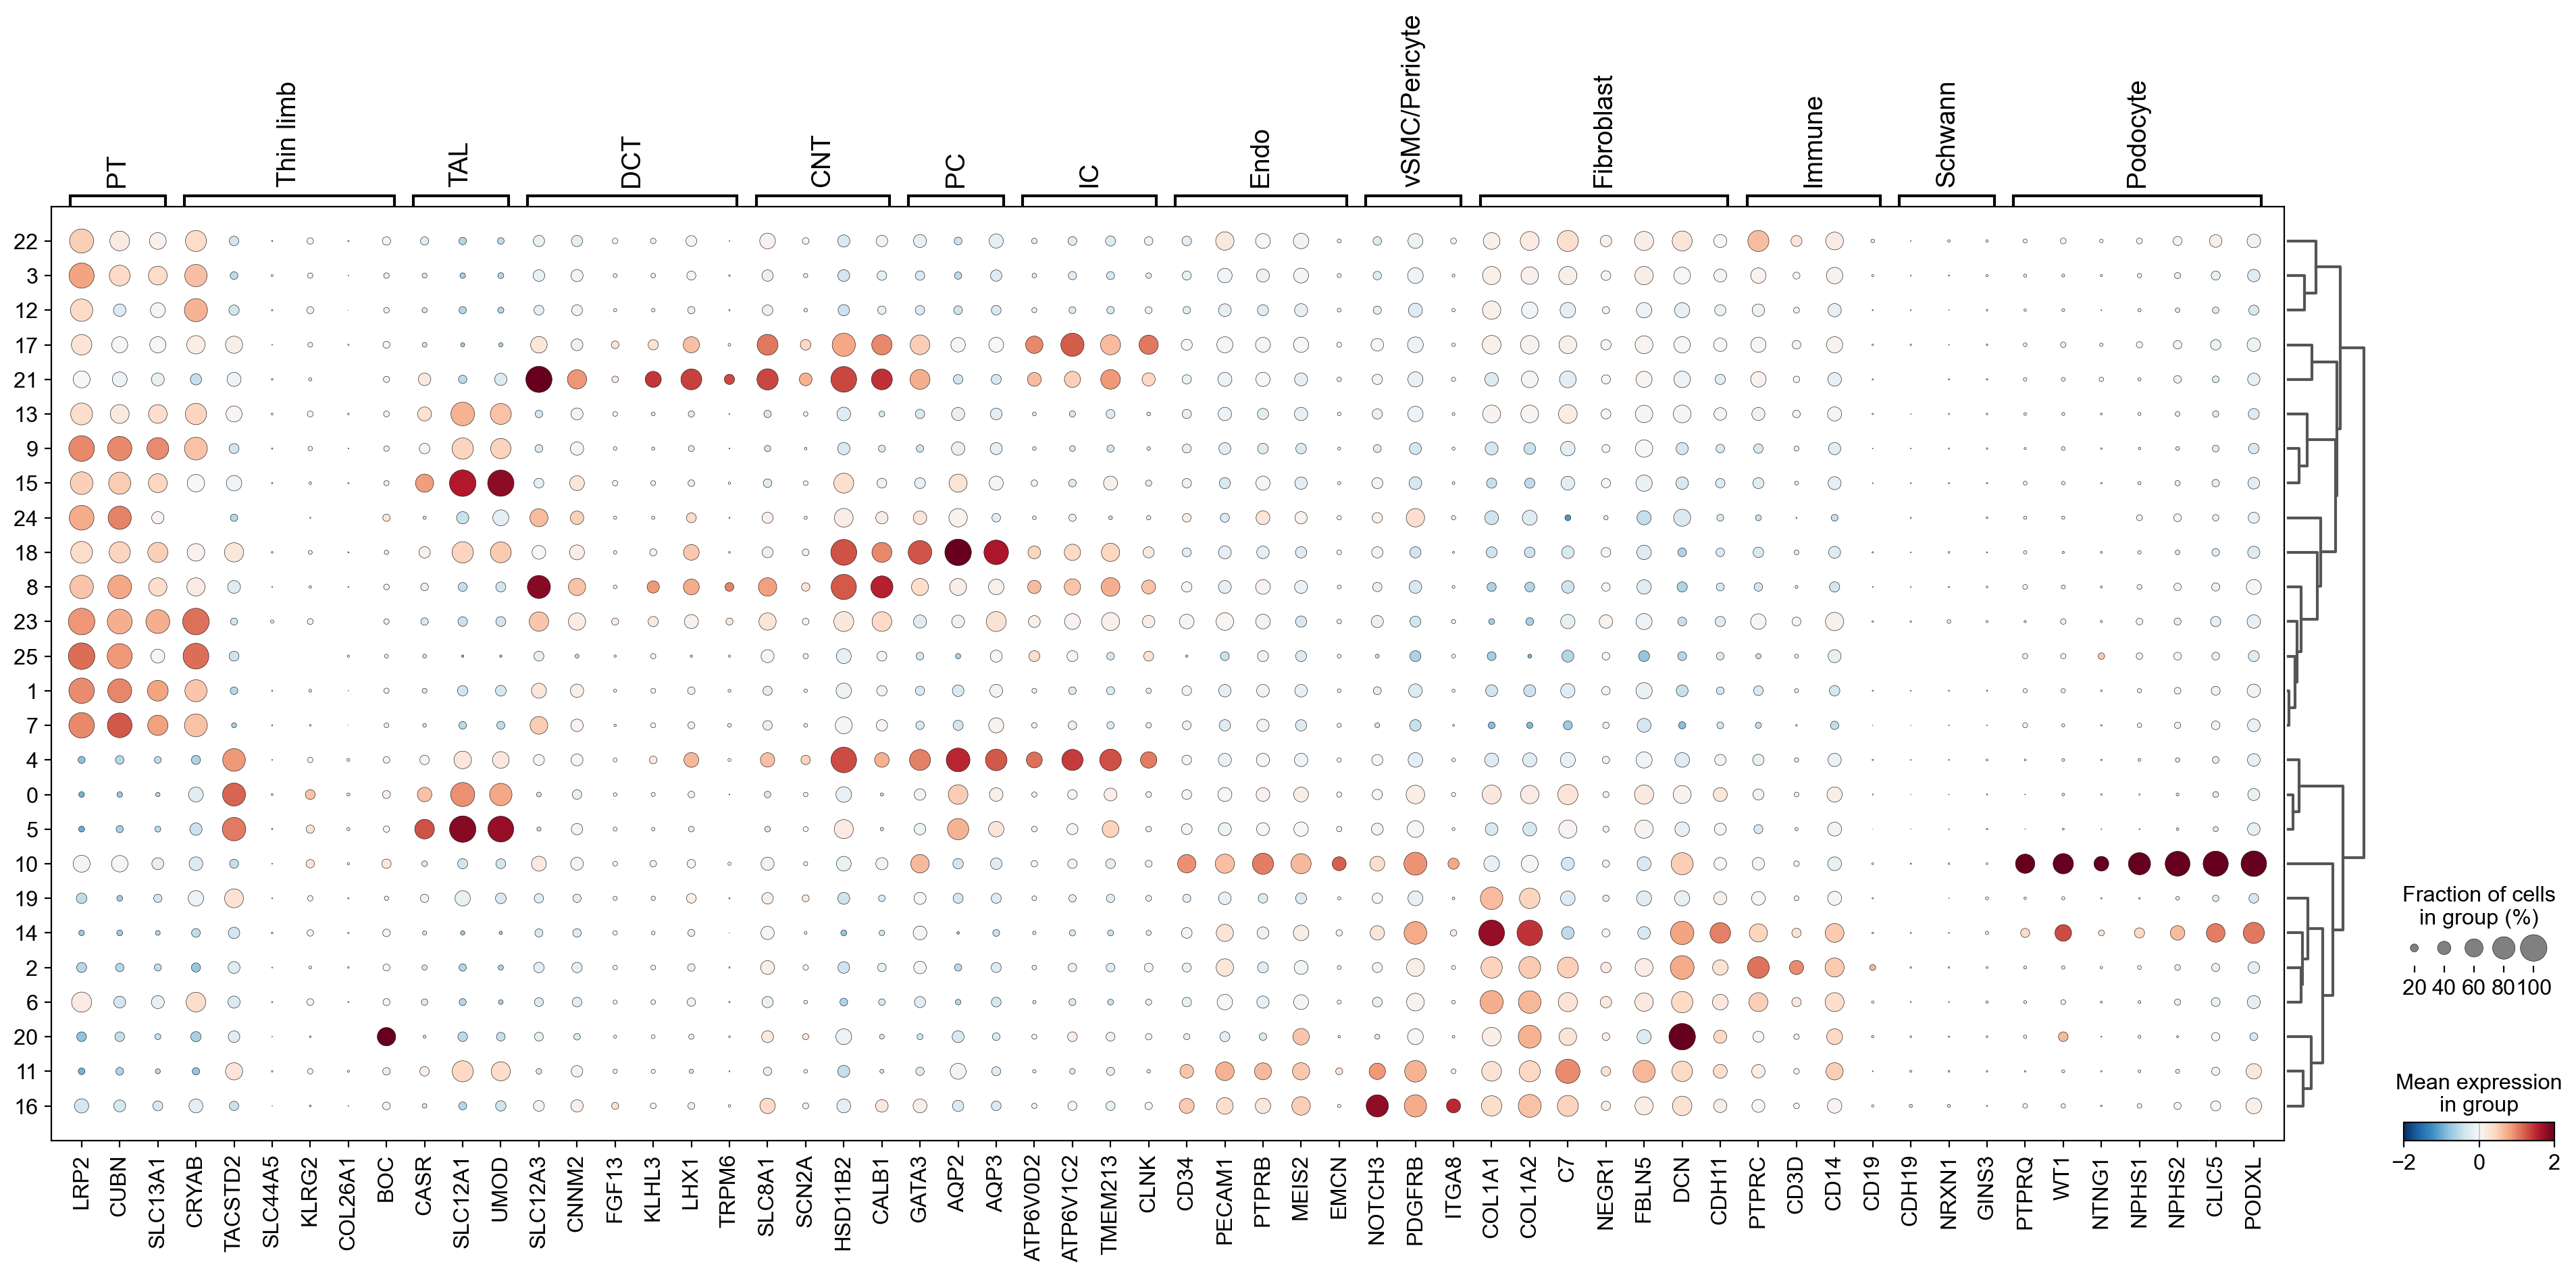

In [15]:
sc.pl.dotplot(tmp, var_names=markers_dict, 
              groupby=f"leiden_{res}", 
              cmap="RdBu_r", vmin=-2, vmax=2, vcenter=0, dendrogram=True, use_raw=False, show=False)#vmax=2, vmin=-2, vcenter=0, show=False)
plt.savefig(os.path.join(figdir, "DOTPLOT_anca_samples_coloredBycurated_markers.pdf"), bbox_inches="tight")

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'leiden_2'}, xlabel='UMAP1', ylabel='UMAP2'>

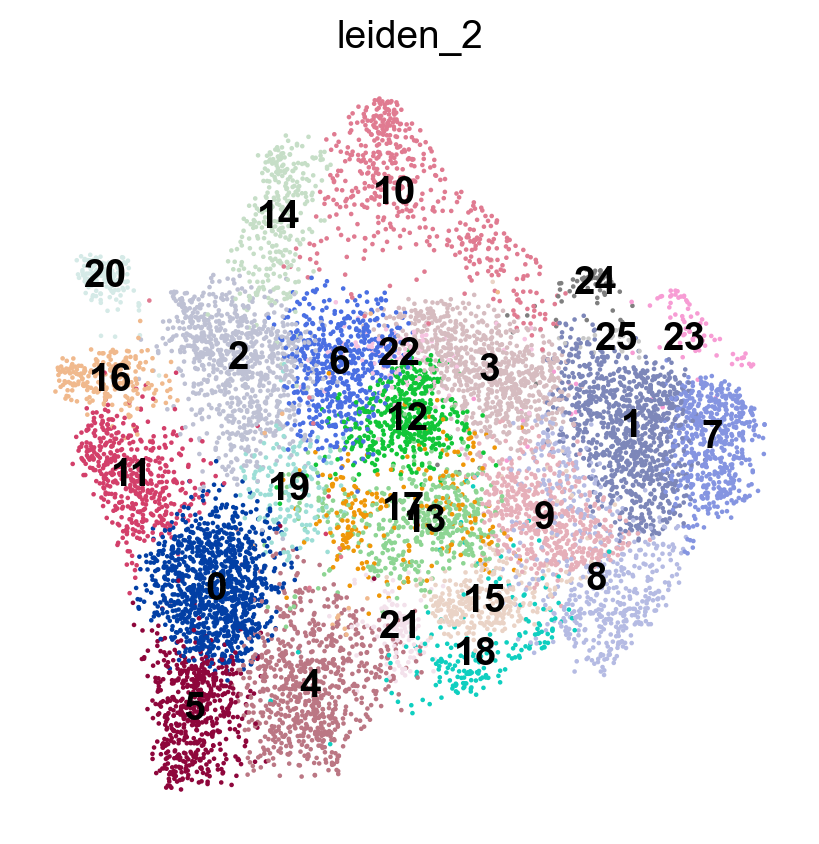

In [16]:
sc.pl.umap(adata, color=f"leiden_{res}", legend_loc="on data", show=False, frameon=False)

In [17]:
adata

AnnData object with n_obs × n_vars = 10976 × 17843
    obs: 'in_tissue', 'array_row', 'array_col', 'Sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'Condition', 'Collecting tubules_score', 'Distal tubules_score', 'intermediate tubules_score', 'interstitium_score', 'proximal tubules_score', 'renal corpuscle_score', 'vessels_score', 'leiden_1', 'region_Cortex_score', 'region_Medulla_score', 'region_Papilla_score', 'leiden_2'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hv

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_anndata.py:771: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(adata.obs[groupby]):
/opt/conda/lib/python3.9/site-packages/seaborn/_core.py:1225: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/conda/lib/python3.9/site-packages/seaborn/categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/opt/conda/lib/python3.9/site-packages/seaborn/_core.py:1225: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future ver

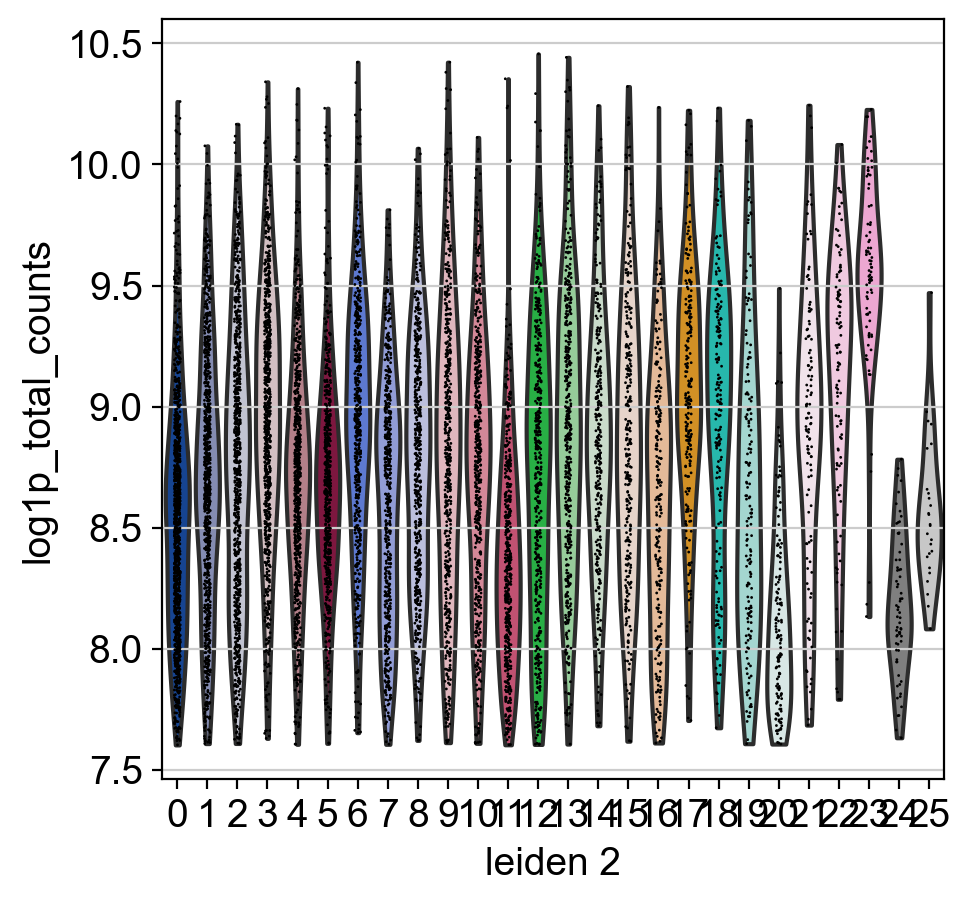

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_anndata.py:771: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(adata.obs[groupby]):
/opt/conda/lib/python3.9/site-packages/seaborn/_core.py:1225: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/conda/lib/python3.9/site-packages/seaborn/categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/opt/conda/lib/python3.9/site-packages/seaborn/_core.py:1225: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future ver

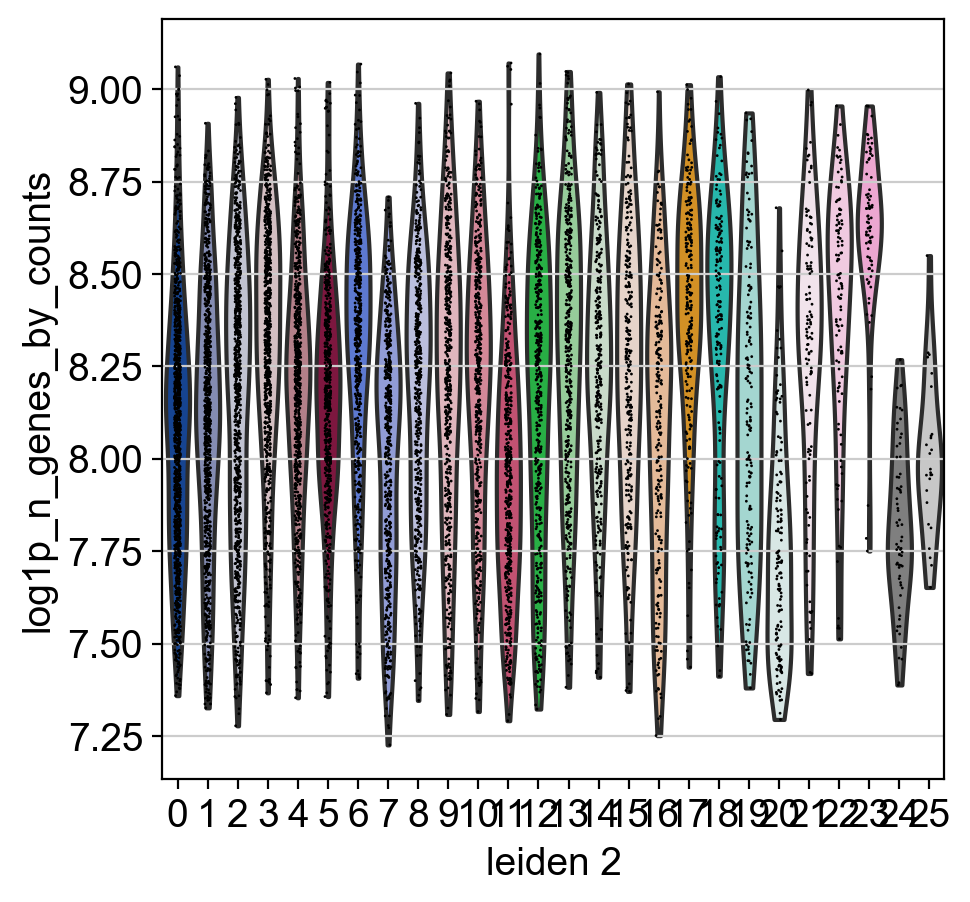

In [18]:
# sc.set_figure_params(figsize=(10,5))
sc.pl.violin(adata, keys="log1p_total_counts", groupby=f"leiden_{res}")
sc.pl.violin(adata, keys="log1p_n_genes_by_counts", groupby=f"leiden_{res}")

In [19]:
rm_clusters = ["20", "24"]
adata = adata[~adata.obs[f"leiden_{res}"].isin(rm_clusters)]

/opt/conda/lib/python3.9/site-packages/anndata/_core/anndata.py:1105: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(df_full[k]):


In [20]:
mapping = {"10": "Normal glomerular",
        "14": "Inflamed glomerular",
        "22": "PT",
        "3": "PT",
        "12": "PT",
        "23": "PT",
        "25": "PT",
        "1": "PT",
        "7": "PT",
        "3": "PT",       
        "2": "Inflamed tubulointerstitial",
        "6": "Inflamed tubulointerstitial",
        "22": "PT",
        "24": "PT",
        "0": "LOH",
        "5": "LOH",
        "9": "PT/LOH",
        "13": "PT/LOH",
        "15": "PT/LOH",
        "8": "PT/DCT",
        "11": "Vasculature",
        "16": "Vasculature",
        "20": "Vasculature",
        "19": "Tubulointerstitial",
        "21": "DCT/CNT",
       "4": "CNT/PC/IC",
        "17": "CNT/PC/IC",
        "18": "CNT/PC",    
          }
           

In [21]:
adata.obs["cluster_annot"] = adata.obs[f"leiden_{res}"].replace(mapping)

/tmp/ipykernel_2941267/1935103041.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["cluster_annot"] = adata.obs[f"leiden_{res}"].replace(mapping)


In [22]:
col_order = ["PT", "PT/DCT", "DCT/CNT", "CNT/PC", "CNT/PC/IC", "PT/LOH", "LOH",
         "Tubulointerstitial", "Vasculature", "Normal glomerular", "Inflamed glomerular", "Inflamed tubulointerstitial"]

In [23]:
adata.obs["cluster_annot"] = adata.obs["cluster_annot"].cat.reorder_categories(col_order[::-1])

In [24]:
# sc.pl.umap(adata, color="cluster_annot", legend_loc="right margin", show=False, frameon=False, legend_fontoutline=3, title="Niche")

In [25]:
# sc.pl.umap(adata, color="cluster_annot", legend_loc="on data", show=False, frameon=False, legend_fontsize=7,
#            legend_fontoutline=3)

In [26]:
alpha = 99

In [27]:
# current_colors = dict(zip(adata.obs["cluster_annot"].cat.categories.tolist(), adata.uns["cluster_annot_colors"].copy()))

# colors_dict = {"PT": "#bdc9e1ff",
#                "PT/DCT": "#2b8cbea5",
#                "DCT/CNT": "#9e77c8c6", 
#                "PT/LOH": "#ff5db2",
#                "CNT/PC": "#9970cfc9",
#                "CNT/PC/IC": "#c2a8cfff",
#                "LOH": "#e7d4e8ff",
#                
#                "Tubulointerstitial": "#d9f0d3ff",
#                
#                "Vasculature": "#a6dba0ff",
#                
#                "Normal glomerular": "#b0d12eff",
#                
#                "Inflamed glomerular": "#1b7837ff",
#                "Inflamed tubulointerstitial": "#00441bff"
#               } # old

colors_dict = {"Inflamed tubulointerstitial": "#cb181d",
                "Inflamed glomerular": "#fb6a4a",
                "Normal glomerular": "#568203",
                "Vasculature": "#9acd32",
                "Tubulointerstitial": "#d0db61",
                "PT": f"#BDC9E1{alpha}",
                "PT/LOH": f"#74A9CF{alpha}",
                "LOH": f"#2B8CBE{alpha}",
                "PT/DCT": f"#045A8D{alpha}",
                "DCT/CNT": f"#9E9AC8{alpha}",
                "CNT/PC": f"#756BB1{alpha}",
                "CNT/PC/IC": f"#54278F{alpha}",
                }


In [28]:
colors = []
for cat in adata.obs["cluster_annot"].cat.categories:
    colors.append(colors_dict[cat])
adata.uns["cluster_annot_colors"] = colors

In [29]:
import pickle

In [30]:
colors_dict = dict(zip(adata.obs["cluster_annot"].cat.categories.tolist(), adata.uns["cluster_annot_colors"].copy()))
with open(os.path.join(datadir, 'cluster_annot_colors.pkl'), 'wb') as handle:
    pickle.dump(colors_dict, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [31]:
# sc.pl.umap(adata, color="cluster_annot", title="", legend_loc="on data", frameon=False, s=7, show=False, legend_fontoutline=3, legend_fontsize=7)
# plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_on_top.pdf"), bbox_inches="tight")
# 
# sc.pl.umap(adata, color="cluster_annot", title="", frameon=False, s=7, show=False)
# plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_on_side.pdf"), bbox_inches="tight")

In [32]:
# sc.pl.umap(adata, color="cluster_annot", title="", frameon=True, s=7, show=False)
# plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_on_side_border.pdf"), bbox_inches="tight")

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


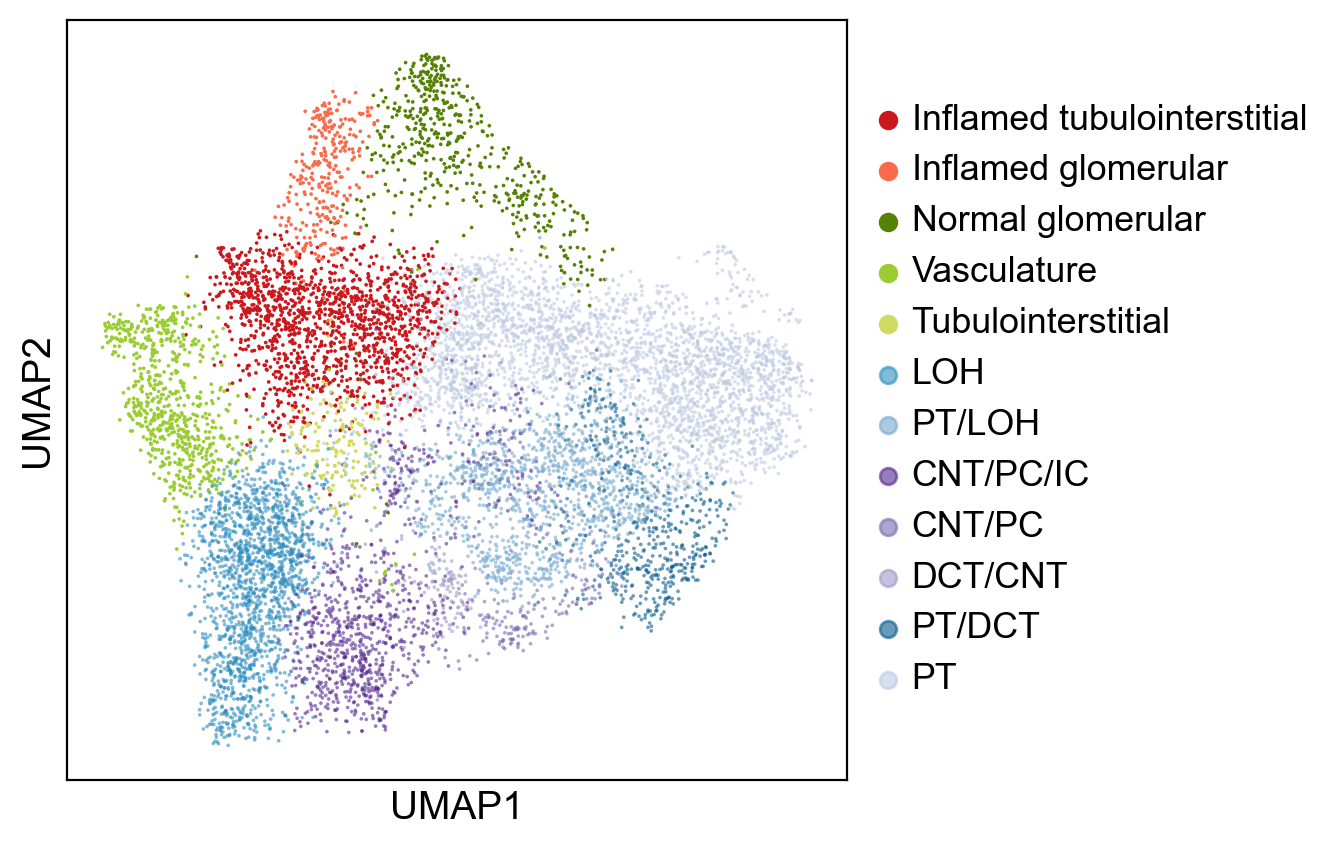

In [33]:
sc.pl.umap(adata, color="cluster_annot", title="", frameon=True, s=7, show=False)
plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_on_side_border_ordered.pdf"), 
            bbox_inches="tight")

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


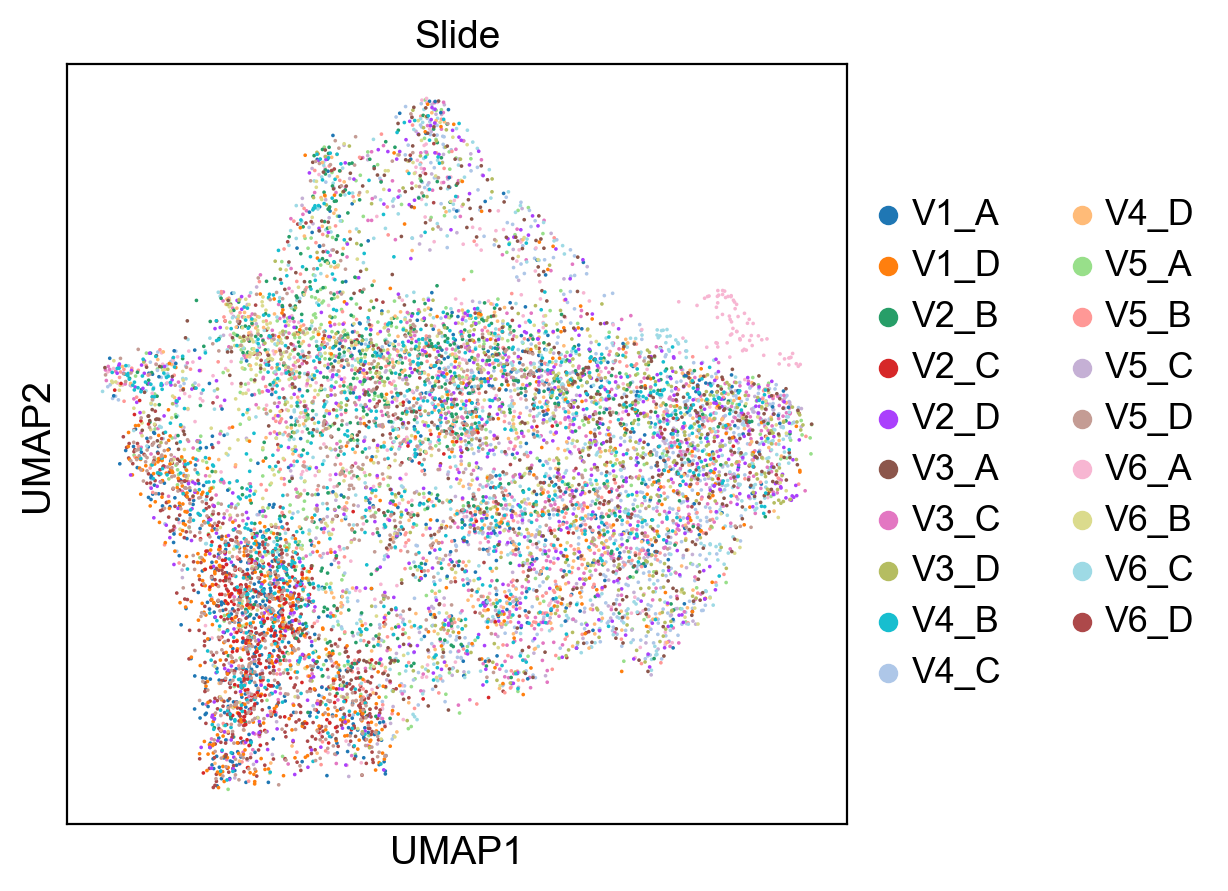

In [34]:
sc.pl.umap(adata, color="Sample", title="Slide", frameon=True, s=7, show=False)
plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredBySlide_on_side_border.pdf"), bbox_inches="tight")

In [35]:
keep_clusters = ["Normal glomerular", "Inflamed glomerular", "Tubulointerstitial", "Vasculature", 
                 "Inflamed tubulointerstitial"]
tubule_clusters = []
for cluster in adata.obs.cluster_annot.unique():
    if cluster not in keep_clusters:
        tubule_clusters.append(cluster)
broad_mapping = dict(zip(tubule_clusters, ["Tubular"]*len(tubule_clusters)))

adata.obs["cluster_annot_broad"] = adata.obs.cluster_annot.replace(broad_mapping)

In [36]:
# sc.pl.umap(adata, color="cluster_annot_broad", title="", legend_loc="on data", frameon=False, s=7, show=False, legend_fontoutline=3, legend_fontsize=7)

In [37]:
# current_colors = dict(zip(adata.obs["cluster_annot_broad"].cat.categories.tolist(), adata.uns["cluster_annot_broad_colors"].copy()))

colors_dict = {"Tubular": "#BDC9E1",
               "Tubulointerstitial": "#c49c94",
               "Vasculature": "#219EBC", #
               "Normal glomerular": "#d2d40b",
               "Inflamed glomerular": "#d62728",
               "Inflamed tubulointerstitial": "#900D09"
              }

In [38]:
colors = []
for cat in adata.obs["cluster_annot_broad"].cat.categories:
    colors.append(colors_dict[cat])
adata.uns["cluster_annot_broad_colors"] = colors

In [39]:
import pickle

In [40]:
colors_dict = dict(zip(adata.obs["cluster_annot_broad"].cat.categories.tolist(), adata.uns["cluster_annot_broad_colors"].copy()))
with open(os.path.join(datadir, 'cluster_annot_broad_colors.pkl'), 'wb') as handle:
    pickle.dump(colors_dict, handle, protocol=pickle.HIGHEST_PROTOCOL)

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future versio

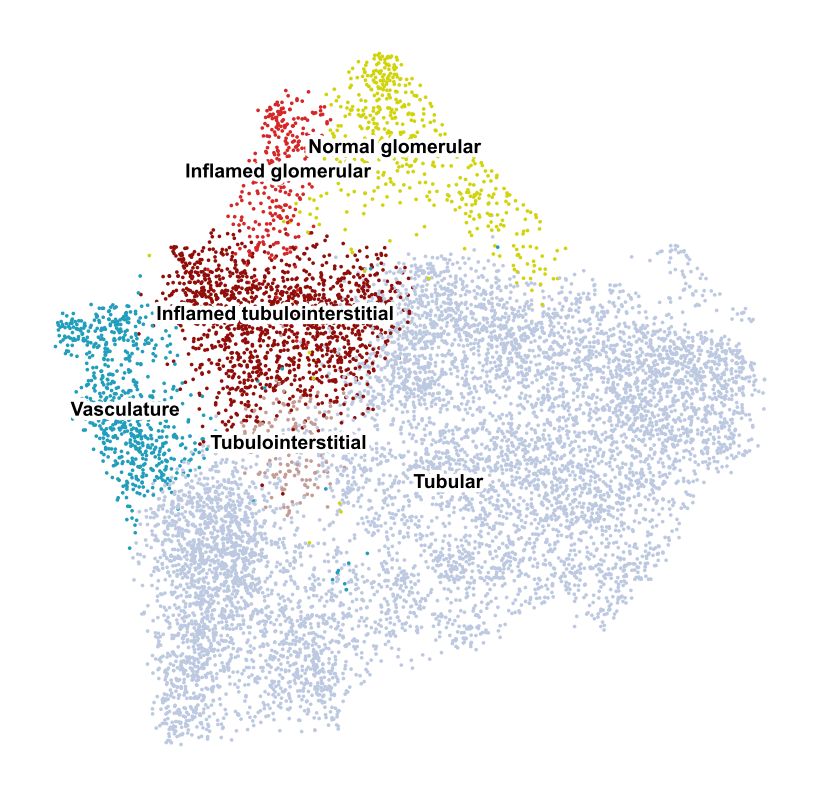

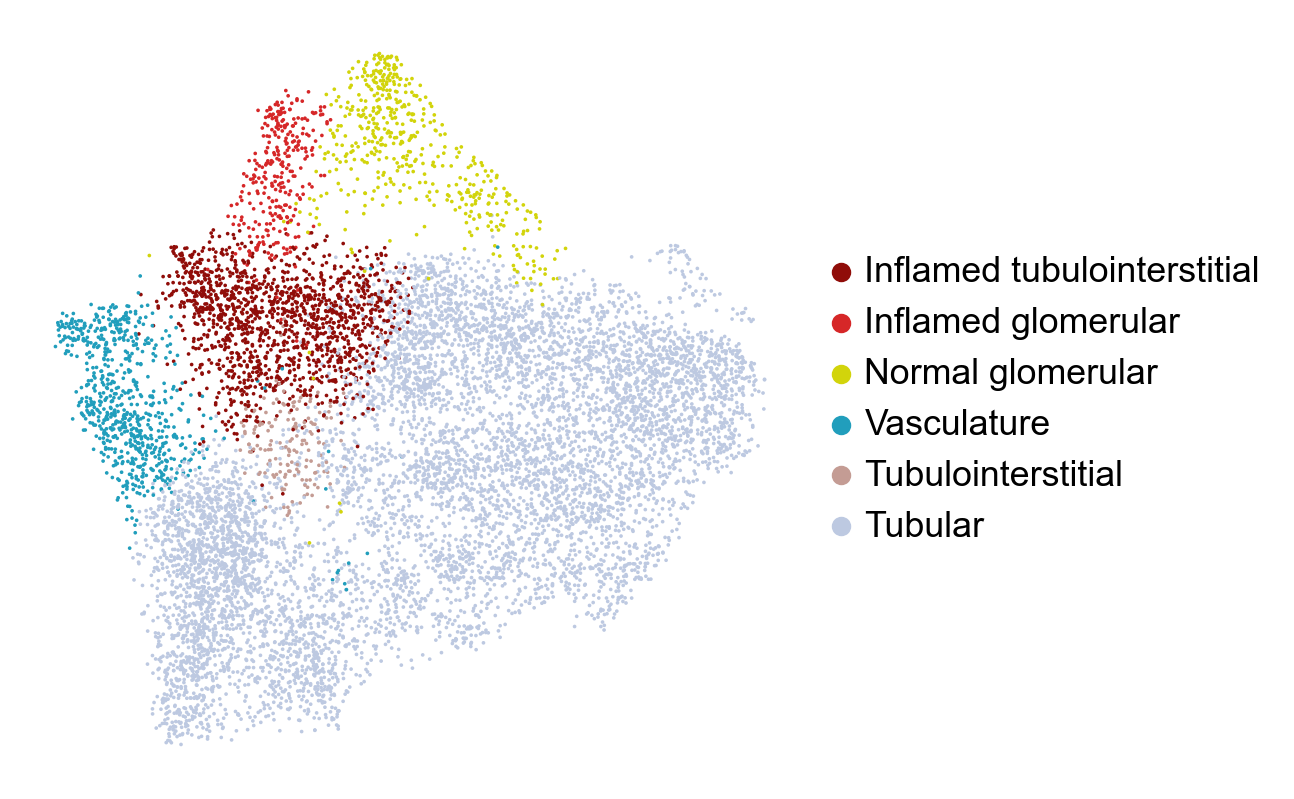

In [41]:
sc.pl.umap(adata, color="cluster_annot_broad", title="", legend_loc="on data", frameon=False, s=7, show=False, 
           legend_fontoutline=3, legend_fontsize=7)
plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_broad_on_top.pdf"), bbox_inches="tight")

sc.pl.umap(adata, color="cluster_annot_broad", title="", frameon=False, s=7, show=False)
plt.savefig(os.path.join(figdir, "UMAP_anca_samples_coloredByCluster_annot_broad_on_side.pdf"), bbox_inches="tight")

In [42]:
def show_spatial_one(clst_in):
    sc.set_figure_params(dpi=200)
    for sample in adata.obs.Sample.unique():
        tmp = adata[adata.obs.Sample==sample]
        tmp_colors = []
        for clst in tmp.obs.cluster_annot.cat.categories:
            if clst==clst_in:
                tmp_colors.append("yellow")
            else:
                tmp_colors.append("none")
        tmp.uns["cluster_annot_colors"] = tmp_colors
        sc.pl.spatial(tmp, color=[None, "cluster_annot"], library_id=sample, title=sample, alpha_img=0.7)
    sc.set_figure_params(dpi=100)
    plt.show()
    
def show_spatial_two(clst_in_1, clst_in_2):
    sc.set_figure_params(dpi=200)
    for sample in adata.obs.Sample.unique():
        tmp = adata[adata.obs.Sample==sample]
        tmp_colors = []
        for clst in tmp.obs.cluster_annot.cat.categories:
            if clst==clst_in_1:
                tmp_colors.append("yellow")
            elif clst==clst_in_2:
                tmp_colors.append("red")
            else:
                tmp_colors.append("none")
        tmp.uns["cluster_annot_colors"] = tmp_colors
        sc.pl.spatial(tmp, color=[None, "cluster_annot"], library_id=sample, title=sample, alpha_img=0.7)
    sc.set_figure_params(dpi=100)
    plt.show()

In [43]:
import warnings
warnings.filterwarnings("default")

In [44]:
image_figdir = os.path.join(figdir, "cluster_on_images")
if not os.path.exists(image_figdir):
    os.mkdir(image_figdir)

In [45]:
alpha = ""
colors_dict = {"Inflamed tubulointerstitial": "#cb181d",
                "Inflamed glomerular": "#fb6a4a",
                "Normal glomerular": "#568203",
                "Vasculature": "#9acd32",
                "Tubulointerstitial": "#d0db61",
                "PT": f"#BDC9E1{alpha}",
                "PT/LOH": f"#74A9CF{alpha}",
                "LOH": f"#2B8CBE{alpha}",
                "PT/DCT": f"#045A8D{alpha}",
                "DCT/CNT": f"#9E9AC8{alpha}",
                "CNT/PC": f"#756BB1{alpha}",
                "CNT/PC/IC": f"#54278F{alpha}",
                }


In [46]:
colors = []
for cat in adata.obs["cluster_annot"].cat.categories:
    colors.append(colors_dict[cat])
adata.uns["cluster_annot_colors"] = colors

In [47]:
colors_dict = dict(zip(adata.obs["cluster_annot"].cat.categories.tolist(), adata.uns["cluster_annot_colors"].copy()))
with open(os.path.join(datadir, 'cluster_annot_colors_noAlpha.pkl'), 'wb') as handle:
    pickle.dump(colors_dict, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [48]:
sc.set_figure_params(dpi=500, dpi_save=500)
import matplotlib
from matplotlib import font_manager
font_dirs = "/usr/share/fonts/truetype/msttcorefonts/"
font_files = font_manager.findSystemFonts(fontpaths=font_dirs)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

matplotlib.pyplot.rcParams['font.family'] = "arial"    

for sample in adata.obs.Sample.unique():
    tmp = adata[adata.obs.Sample==sample]
    sc.pl.spatial(tmp, color=[None, "cluster_annot"], library_id=sample, title=[sample, "cluster"],
                  alpha_img=0.7, s=10, show=False,
                 ncols=1)
    plt.savefig(os.path.join(image_figdir, f"SPATIALSCATTER_{sample}_coloredByCluster_annot_hires.pdf"), bbox_inches="tight",
               dpi=500)
    plt.clf()

/opt/conda/lib/python3.9/site-packages/scanpy/_settings.py:447: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  IPython.display.set_matplotlib_formats(*ipython_format)
/opt/conda/lib/python3.9/site-packages/anndata/_core/anndata.py:1105: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(df_full[k]):
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:163: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = copy(get_cmap(cmap))
/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will b

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

... (10 outputs left out)

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

<Figure size 2415x4000 with 0 Axes>

In [49]:
!pdfunite ../figures/cluster_on_images/*_coloredByCluster_annot_hires.pdf ../figures/cluster_on_images/supplementary_file_1.pdf

In [ ]:
sc.set_figure_params(dpi=100)
import matplotlib
from matplotlib import font_manager
font_dirs = "/usr/share/fonts/truetype/msttcorefonts/"
font_files = font_manager.findSystemFonts(fontpaths=font_dirs)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

matplotlib.pyplot.rcParams['font.family'] = "arial"   

/opt/conda/lib/python3.9/site-packages/scanpy/_settings.py:447: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  IPython.display.set_matplotlib_formats(*ipython_format)


In [ ]:
alpha = 0.6

In [ ]:
colors_dict = {"Inflamed tubulointerstitial": "#cb181d",
                "Inflamed glomerular": "#fb6a4a",
                "Normal glomerular": "#568203",
                "Vasculature": "#9acd32",
                "Tubulointerstitial": "#d0db61",
                "PT": f"#BDC9E1{alpha}",
                "PT/LOH": f"#74A9CF{alpha}",
                "LOH": f"#2B8CBE{alpha}",
                "PT/DCT": f"#045A8D{alpha}",
                "DCT/CNT": f"#9E9AC8{alpha}",
                "CNT/PC": f"#756BB1{alpha}",
                "CNT/PC/IC": f"#54278F{alpha}",
                }

In [ ]:
colors = []
for cat in adata.obs["cluster_annot"].cat.categories:
    colors.append(colors_dict[cat])
adata.uns["cluster_annot_colors"] = colors

In [ ]:
adata.write(os.path.join(datadir, "anca_samples_clustered_modifiedColors.h5ad"))

In [ ]:
adata.obs["Sample"].value_counts().shape

(19,)

In [ ]:
adata.write(os.path.join(datadir, "anca_samples_clustered.h5ad"))

In [ ]:
adata = sc.read(os.path.join(datadir, "anca_samples_clustered.h5ad"))
sample = "V1_D"
sub = adata[adata.obs.Sample==sample]

/opt/conda/lib/python3.9/site-packages/anndata/_core/anndata.py:1105: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(df_full[k]):


In [ ]:
# sc.set_figure_params(dpi=200)
# sc.pl.spatial(sub, library_id=sample, color="cluster_annot",s=10, alpha_img=0.7)

In [ ]:
# sub.uns["cluster_annot_colors"]

In [ ]:
# sub.uns["cluster_annot_colors"] = sns.color_palette("colorblind", len(sub.obs["cluster_annot"].unique()))
# sc.set_figure_params(dpi=200)
# sc.pl.spatial(sub, library_id=sample, color="cluster_annot",s=10, alpha_img=0.7)

-----

In [10]:
adata = sc.read(os.path.join(datadir, "anca_samples_clustered.h5ad"))

In [11]:
tmp = adata.copy()
tmp.layers["scaled"] = sc.pp.scale(tmp, max_value=10, copy=True).X

In [49]:
markers = ["LRP2", "SLC12A1", "AQP2", "ACTA2",
          "PECAM1", "COL3A1", "VIM",
          "NPHS1", "NPHS2", "PODXL",
          "PTPRC"]

In [51]:
order = ["Tubular", "Tubulointerstitial", "Vasculature", "Normal glomerular", "Inflamed glomerular", 
         "Inflamed tubulointerstitial"]
tmp.obs["cluster_annot_broad"] = tmp.obs["cluster_annot_broad"].cat.reorder_categories(order)

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_baseplot_class.py:514: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  matplotlib.colorbar.Colorbar(


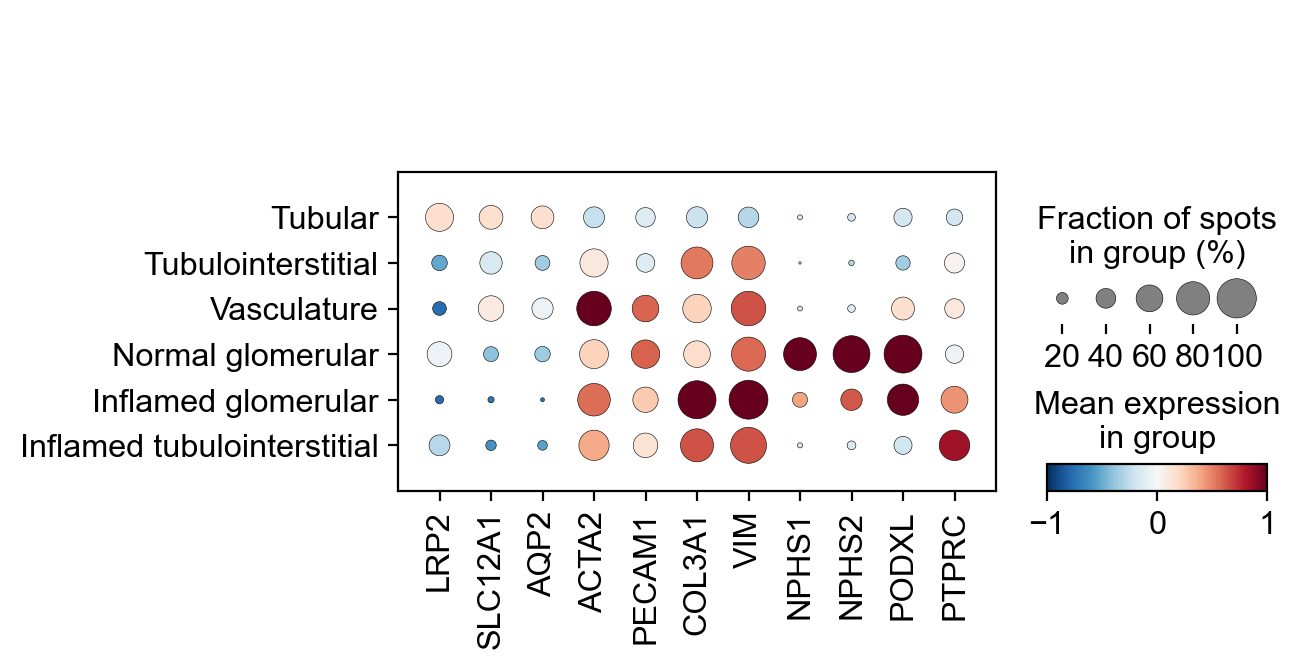

In [52]:
cmap = "RdBu_r"
sc.pl.dotplot(tmp, var_names=markers, groupby="cluster_annot_broad", use_raw=False, cmap=cmap, vmin=-1, vmax=1,
             var_group_rotation=45, show=False, size_title="Fraction of spots\nin group (%)")
plt.savefig(os.path.join(figdir, "DOTPLOT_anca_samples_selected_markers_cluster_annot_broad.pdf"), bbox_inches="tight")

In [33]:
markers_dict = {'PT': ['LRP2', 'CUBN', 'SLC13A1'],
                'DCT': ['SLC12A3', 'CNNM2', 'FGF13', 'KLHL3', 'LHX1', 'TRPM6'],
                'CNT': ['SLC8A1', 'SCN2A', 'HSD11B2', 'CALB1'],
                'PC': ['GATA3', 'AQP2', 'AQP3'],
                'IC': ['ATP6V0D2', 'ATP6V1C2', 'TMEM213', 'CLNK'],
                'Thin limb': ['CRYAB', 'TACSTD2', 'SLC44A5', 'KLRG2', 'COL26A1', 'BOC'],
                'TAL': ['CASR', 'SLC12A1', 'UMOD'],
                'Endo': ['CD34', 'PECAM1', 'PTPRB', 'MEIS2', 'EMCN'],
                'vSMC/Pericyte': ['NOTCH3', 'PDGFRB', 'ITGA8'],
                 'Fibroblast': ['COL1A1', 'COL1A2', 'C7', 'NEGR1', 'FBLN5', 'DCN', 'CDH11'],
                'Podocyte': ['PTPRQ', 'WT1', 'NTNG1', 'NPHS1', 'NPHS2', 'CLIC5', 'PODXL'],
                'Immune': ['PTPRC', 'CD3D', 'CD14', 'CD19'],}

In [34]:
order = ["PT", "PT/DCT", "DCT/CNT", "CNT/PC", "CNT/PC/IC", "PT/LOH", "LOH",
         "Tubulointerstitial", "Vasculature", "Normal glomerular", "Inflamed glomerular", "Inflamed tubulointerstitial"]
tmp.obs["cluster_annot"] = tmp.obs["cluster_annot"].cat.reorder_categories(order)

In [35]:
from matplotlib.colors import LinearSegmentedColormap

In [36]:
def create_colormap():
    colors = [(1, 1, 1), (1, 0, 0)]  # White to Red
    cmap_name = 'white_to_red'
    return LinearSegmentedColormap.from_list(cmap_name, colors, N=1000)

In [37]:
cmap=create_colormap()

In [38]:
sc.set_figure_params(dpi=100, fontsize=15)

In [39]:
import warnings
warnings.filterwarnings("ignore")

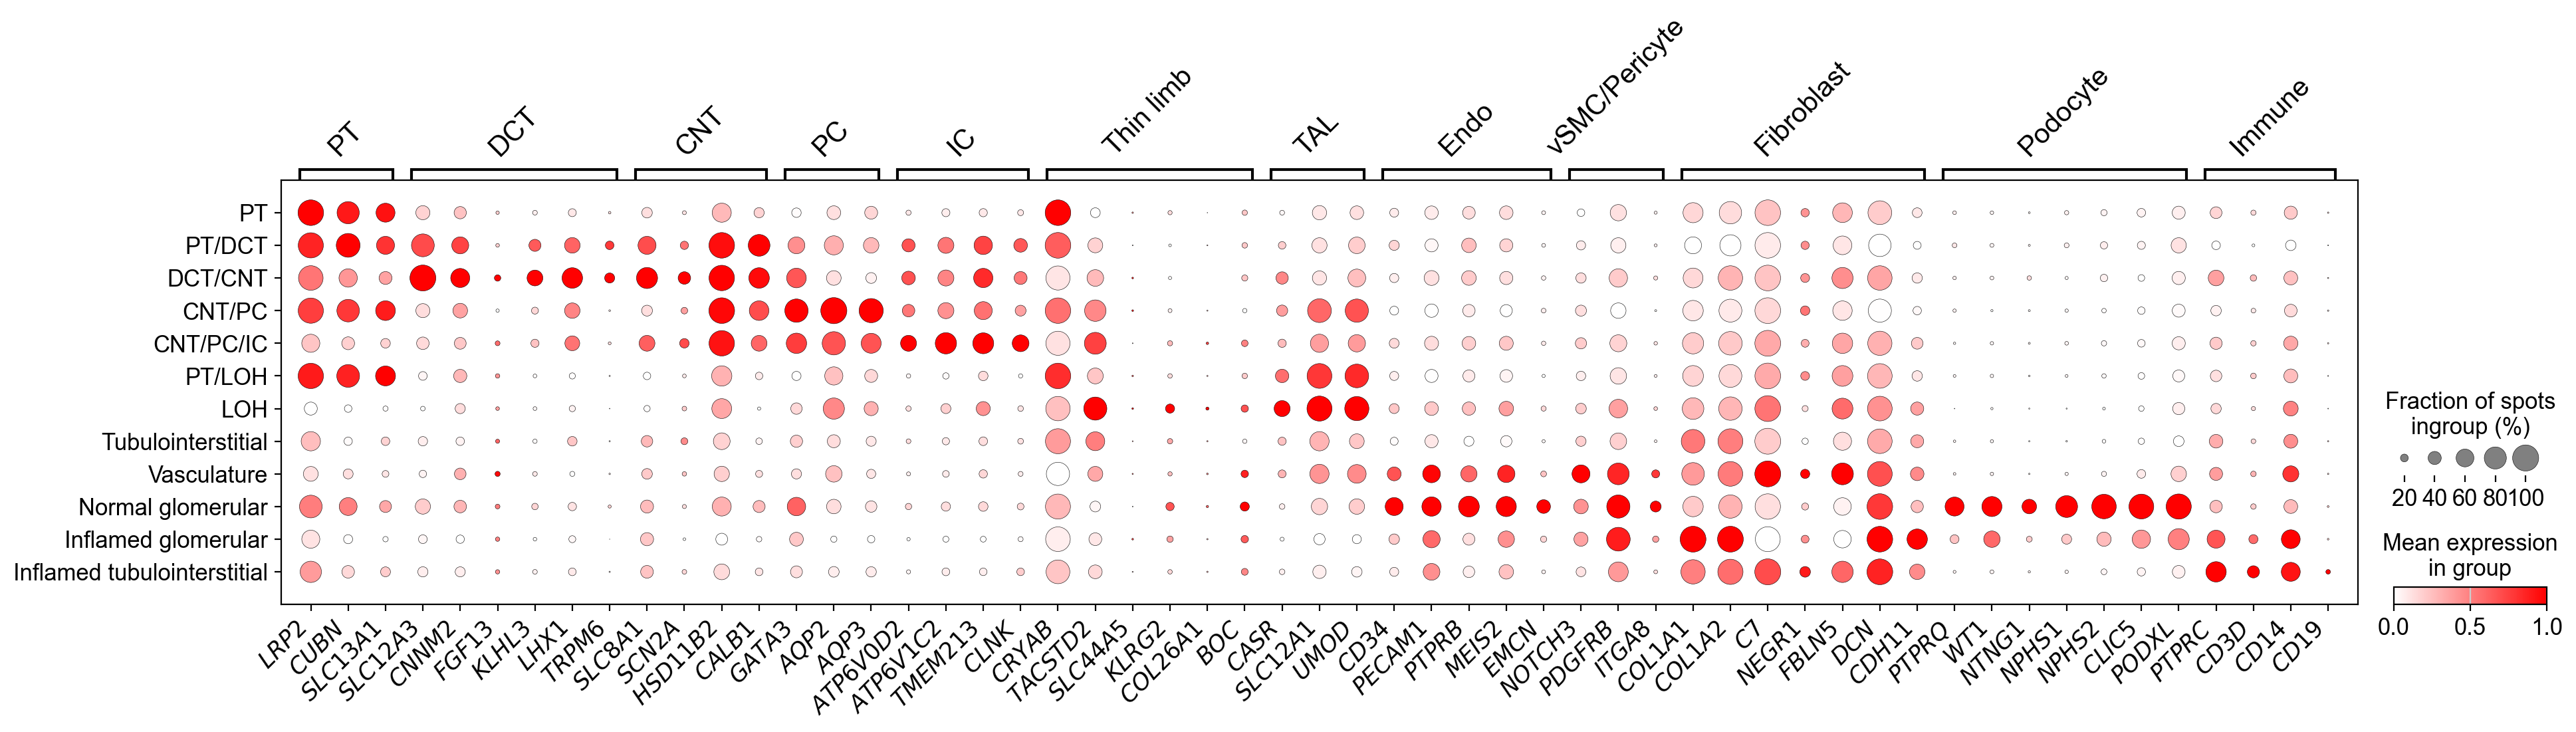

In [40]:
ax=sc.pl.dotplot(tmp, var_names=markers_dict, groupby="cluster_annot", use_raw=False, cmap=cmap, vmax=1,
             var_group_rotation=45, size_title="Fraction of spots\ningroup (%)", standard_scale="var", show=False)
labels = ax["mainplot_ax"].get_xticklabels()
labels = [r"$"+label.get_text()+"$" for label in labels]
ax["mainplot_ax"].set_xticklabels(labels, rotation=45, ha="right")
plt.savefig(os.path.join(figdir, "DOTPLOT_anca_samples_selected_markers_cluster_annot_broad_scaled.pdf"), bbox_inches="tight")

In [27]:
ax

{'mainplot_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of spots\ningroup (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

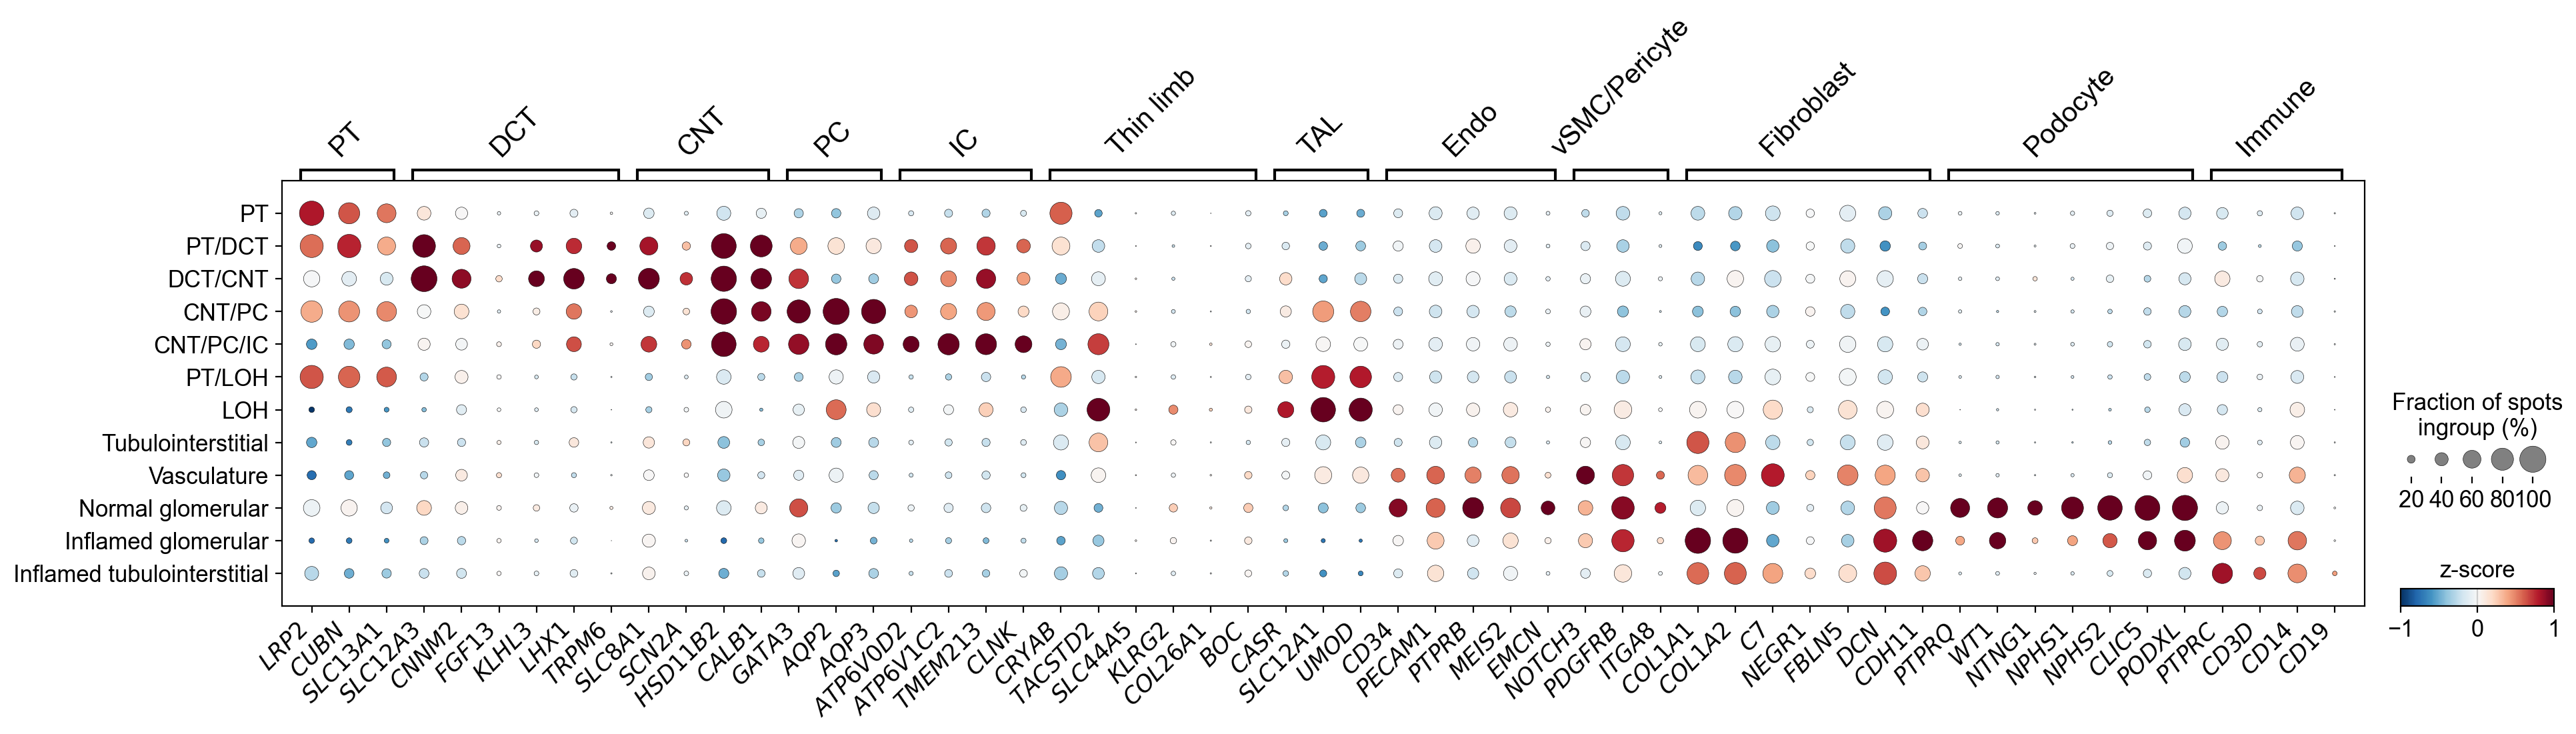

In [43]:
cmap = "RdBu_r"
ax=sc.pl.dotplot(tmp, var_names=markers_dict, groupby="cluster_annot", use_raw=False, cmap=cmap, vmin=-1, vmax=1,
             var_group_rotation=45, show=False, colorbar_title="z-score", size_title="Fraction of spots\ningroup (%)", layer="scaled", )
labels = ax["mainplot_ax"].get_xticklabels()
labels = [r"$"+label.get_text()+"$" for label in labels]
ax["mainplot_ax"].set_xticklabels(labels, rotation=45, ha="right")
plt.savefig(os.path.join(figdir, "DOTPLOT_anca_samples_selected_markers_cluster_annot_broad.pdf"), bbox_inches="tight")

In [56]:
markers_dict = {'PT': ['LRP2', 'CUBN', 'SLC13A1'],
                'DCT': ['SLC12A3', 'CNNM2', 'FGF13', 'KLHL3', 'LHX1', 'TRPM6'],
                'CNT': ['SLC8A1', 'SCN2A', 'HSD11B2', 'CALB1'],
                'PC': ['GATA3', 'AQP2', 'AQP3'],
                'IC': ['ATP6V0D2', 'ATP6V1C2', 'TMEM213', 'CLNK'],
                'Thin limb': ['CRYAB', 'TACSTD2', 'SLC44A5', 'KLRG2', 'COL26A1', 'BOC'],
                'TAL': ['CASR', 'SLC12A1', 'UMOD'],
                'Endo': ['CD34', 'PECAM1', 'PTPRB', 'MEIS2', 'EMCN'],
                'vSMC/Pericyte': ['NOTCH3', 'PDGFRB', 'ITGA8'],
                 'Fibroblast': ['COL1A1', 'COL1A2', 'C7', 'NEGR1', 'FBLN5', 'DCN', 'CDH11'],
                'Podocyte': ['PTPRQ', 'WT1', 'NTNG1', 'NPHS1', 'NPHS2', 'CLIC5', 'PODXL'],
                'Immune': ['PTPRC', 'CD3D', 'CD14', 'CD19'],
                }

/opt/conda/lib/python3.9/site-packages/scanpy/plotting/_baseplot_class.py:514: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  matplotlib.colorbar.Colorbar(


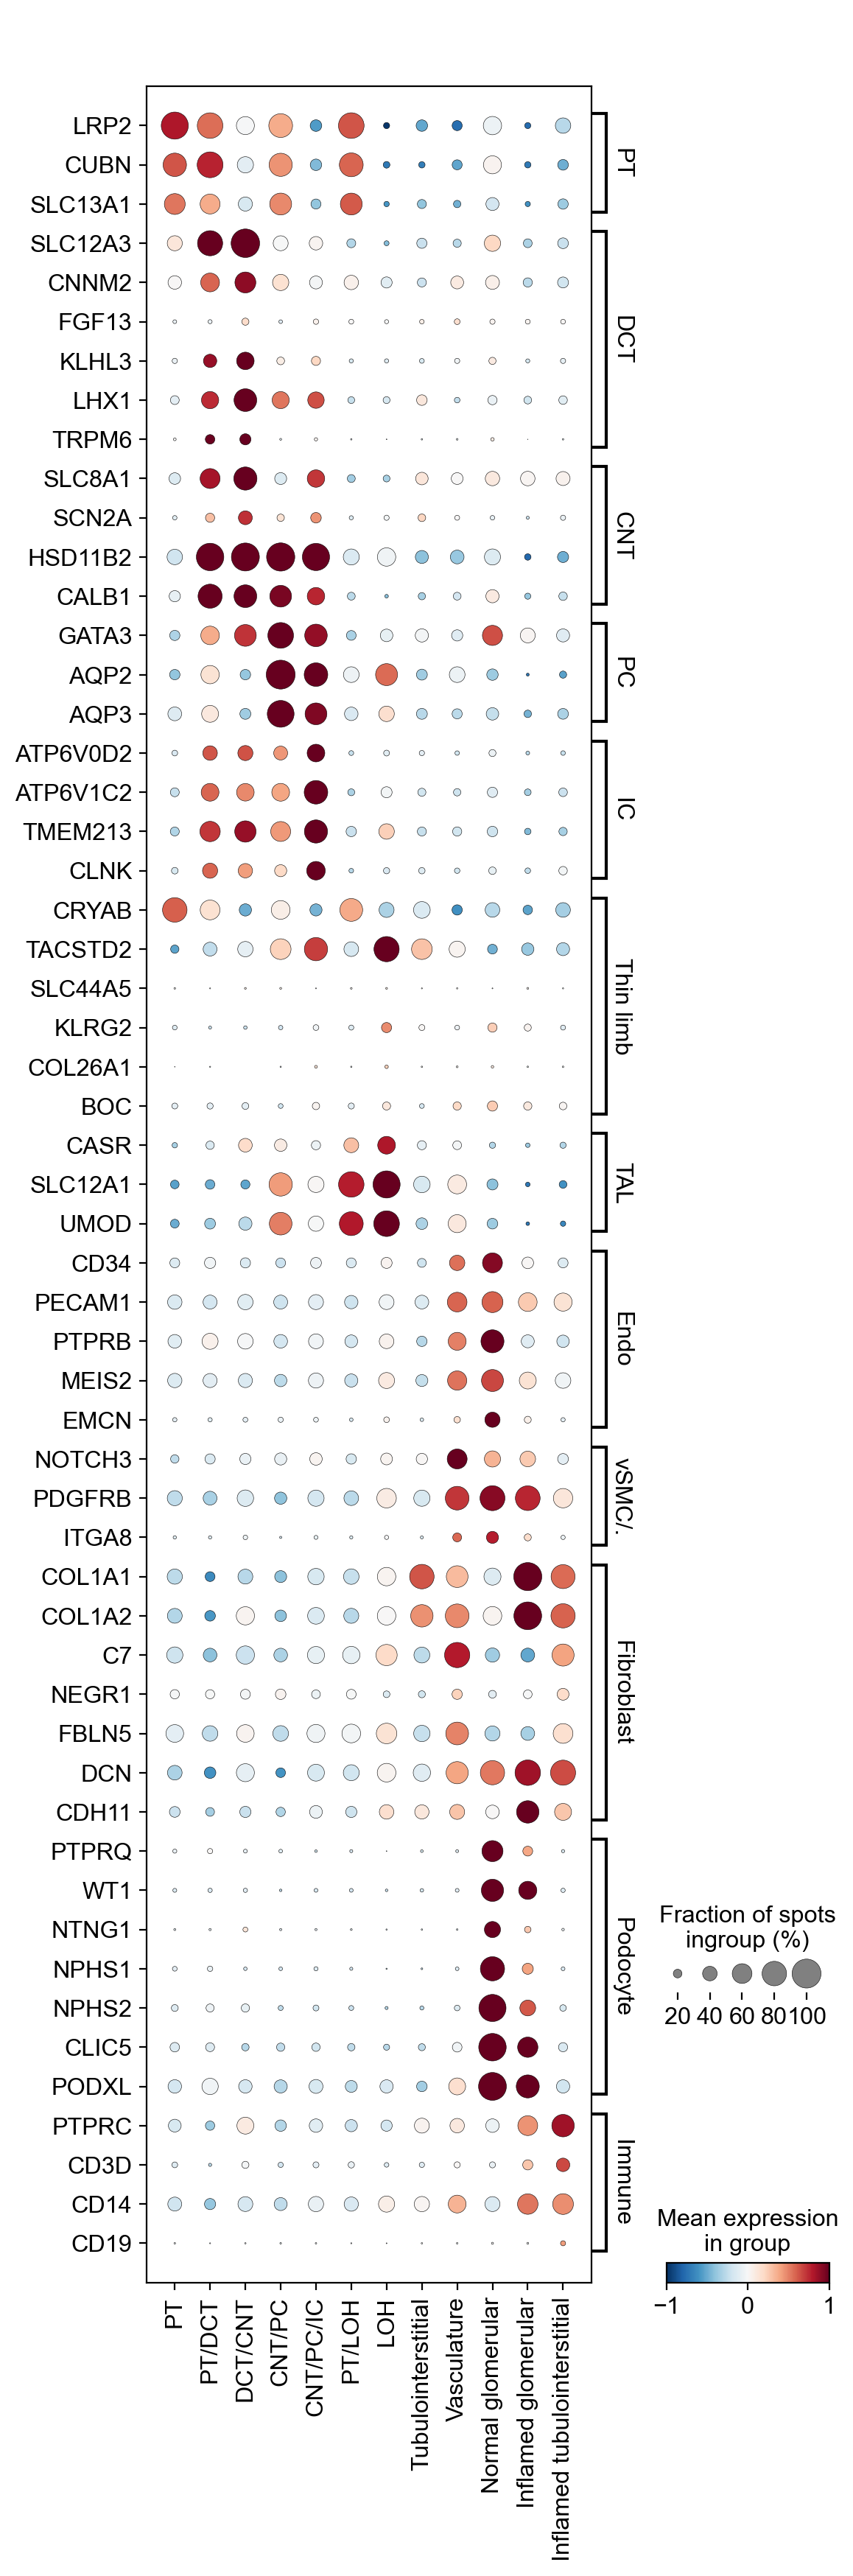

sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7f29380f3a60>


In [57]:
cmap = "RdBu_r"
sc.pl.dotplot(tmp, var_names=markers_dict, groupby="cluster_annot", use_raw=False, cmap=cmap, vmin=-1, vmax=1,
             var_group_rotation=90, show=False, size_title="Fraction of spots\ningroup (%)", swap_axes=True)
plt.savefig(os.path.join(figdir, "DOTPLOT_anca_samples_selected_markers_cluster_annot_broad_rotated.pdf"), 
            bbox_inches="tight")

In [1]:
markers_dict = {'PT': ['LRP2', 'CUBN', 'SLC13A1'],
                'DCT': ['SLC12A3', 'CNNM2', 'FGF13', 'KLHL3', 'LHX1', 'TRPM6'],
                'CNT': ['SLC8A1', 'SCN2A', 'HSD11B2', 'CALB1'],
                'PC': ['GATA3', 'AQP2', 'AQP3'],
                'IC': ['ATP6V0D2', 'ATP6V1C2', 'TMEM213', 'CLNK'],
                'Thin limb': ['CRYAB', 'TACSTD2', 'SLC44A5', 'KLRG2', 'COL26A1', 'BOC'],
                'TAL': ['CASR', 'SLC12A1', 'UMOD'],
                'Endo': ['CD34', 'PECAM1', 'PTPRB', 'MEIS2', 'EMCN'],
                'vSMC/Pericyte': ['NOTCH3', 'PDGFRB', 'ITGA8'],
                 'Fibroblast': ['COL1A1', 'COL1A2', 'C7', 'NEGR1', 'FBLN5', 'DCN', 'CDH11'],
                'Podocyte': ['PTPRQ', 'WT1', 'NTNG1', 'NPHS1', 'NPHS2', 'CLIC5', 'PODXL'],
                'Immune': ['PTPRC', 'CD3D', 'CD14', 'CD19'],
                }

In [6]:
for key in markers_dict:
    print(f"{key}: {', '.join(markers_dict[key])}")

PT: LRP2, CUBN, SLC13A1
DCT: SLC12A3, CNNM2, FGF13, KLHL3, LHX1, TRPM6
CNT: SLC8A1, SCN2A, HSD11B2, CALB1
PC: GATA3, AQP2, AQP3
IC: ATP6V0D2, ATP6V1C2, TMEM213, CLNK
Thin limb: CRYAB, TACSTD2, SLC44A5, KLRG2, COL26A1, BOC
TAL: CASR, SLC12A1, UMOD
Endo: CD34, PECAM1, PTPRB, MEIS2, EMCN
vSMC/Pericyte: NOTCH3, PDGFRB, ITGA8
Fibroblast: COL1A1, COL1A2, C7, NEGR1, FBLN5, DCN, CDH11
Podocyte: PTPRQ, WT1, NTNG1, NPHS1, NPHS2, CLIC5, PODXL
Immune: PTPRC, CD3D, CD14, CD19


In [3]:
adata = sc.read(os.path.join(datadir, "anca_samples_clustered_modifiedColors.h5ad"))

In [7]:
sc.pp.scale(adata, max_value=5)

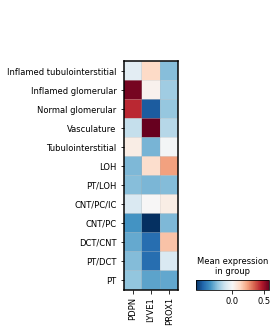

In [15]:
sc.pl.matrixplot(adata, var_names=["PDPN", "LYVE1", "PROX1"], groupby="cluster_annot", use_raw=False, vcenter=0, cmap="RdBu_r")

In [17]:
sc.set_figure_params(dpi=100)

In [ ]:
sc.pl.umap(adata, color=["PDPN", "LYVE1", "PROX1"], use_raw=False, vcenter=0, cmap="RdBu_r", vmax="p99", show=False)